# Step 2: Preprocessing - YOGA Chatbot

**Chatbot Name**: YOGA (YOgyakarta Guide Assistant)

**Objective**: Text preprocessing untuk data teks bahasa Indonesia

**Date**: 2025-11-24

**Dataset**: 92 intents from intents_diy_full.json dengan 1326 patterns

**Preprocessing Steps (NLP Traditional)**:
1. Load dataset
2. Text normalization (case folding, remove special chars)
3. Tokenization (word-level)
4. Stopword removal (Indonesian - Sastrawi)
5. Stemming (Sastrawi)
6. Save preprocessed text

**Note**: 
- Keras tokenization, padding, label encoding akan dilakukan di **Step 3 (Feature Extraction)**
- Train-test split akan dilakukan di **Step 3 (Feature Extraction)**
- Word Embedding akan dilakukan di **Step 4 (LSTM Modeling)**

## 1. Import Libraries

## 2. Load Dataset

In [75]:
# Load intents dataset (FULL VERSION - ORIGINAL DATA)
with open('../data/intents_diy_full.json', 'r', encoding='utf-8') as f:
    data = json.load(f)

intents = data['intents']

print("=" * 80)
print("DATASET LOADED (FULL - ORIGINAL DATA)")
print("=" * 80)
print(f"Total Intents: {len(intents)}")
print(f"\nSample intent tags:")
for i, intent in enumerate(intents[:10], 1):
    print(f"  {i}. {intent['tag']} ({len(intent['patterns'])} patterns)")

DATASET LOADED (FULL - ORIGINAL DATA)
Total Intents: 88

Sample intent tags:
  1. greeting (25 patterns)
  2. pagi (25 patterns)
  3. siang (25 patterns)
  4. sore (25 patterns)
  5. malam (25 patterns)
  6. goodbye (25 patterns)
  7. provinsi_DIY (25 patterns)
  8. kabupaten_bantul (35 patterns)
  9. kabupaten_gunungkidul (25 patterns)
  10. kabupaten_kulonprogo (25 patterns)


## 3. Extract Patterns and Labels

In [76]:
# Extract patterns and labels
patterns = []
labels = []

for intent in intents:
    tag = intent['tag']
    for pattern in intent['patterns']:
        patterns.append(pattern)
        labels.append(tag)

print("=" * 80)
print("DATA EXTRACTION")
print("=" * 80)
print(f"Total patterns: {len(patterns)}")
print(f"Total labels: {len(labels)}")
print(f"Unique labels: {len(set(labels))}")

# Create DataFrame
df = pd.DataFrame({
    'pattern': patterns,
    'label': labels
})

print(f"\nDataFrame shape: {df.shape}")
print(f"\nFirst 10 rows:")
df.head(10)

DATA EXTRACTION
Total patterns: 2247
Total labels: 2247
Unique labels: 88

DataFrame shape: (2247, 2)

First 10 rows:


,pattern,label
0,halo,greeting
1,hai,greeting
2,hey,greeting
3,hello,greeting
4,hi,greeting
5,halo yoga,greeting
6,hai yoga,greeting
7,hello yoga,greeting
8,hey yoga,greeting
9,halo bot,greeting


## 4. Label Distribution

LABEL DISTRIBUTION

Top 10 labels:
label
kabupaten_sleman       36
kecamatan_kalasan      36
kabupaten_bantul       35
kecamatan_prambanan    34
kecamatan_ngawen       28
kecamatan_sedayu       28
kecamatan_panjatan     25
kecamatan_ponjong      25
kecamatan_pleret       25
kecamatan_playen       25
Name: count, dtype: int64

Statistics:
  Mean: 25.53
  Median: 25
  Min: 25
  Max: 36


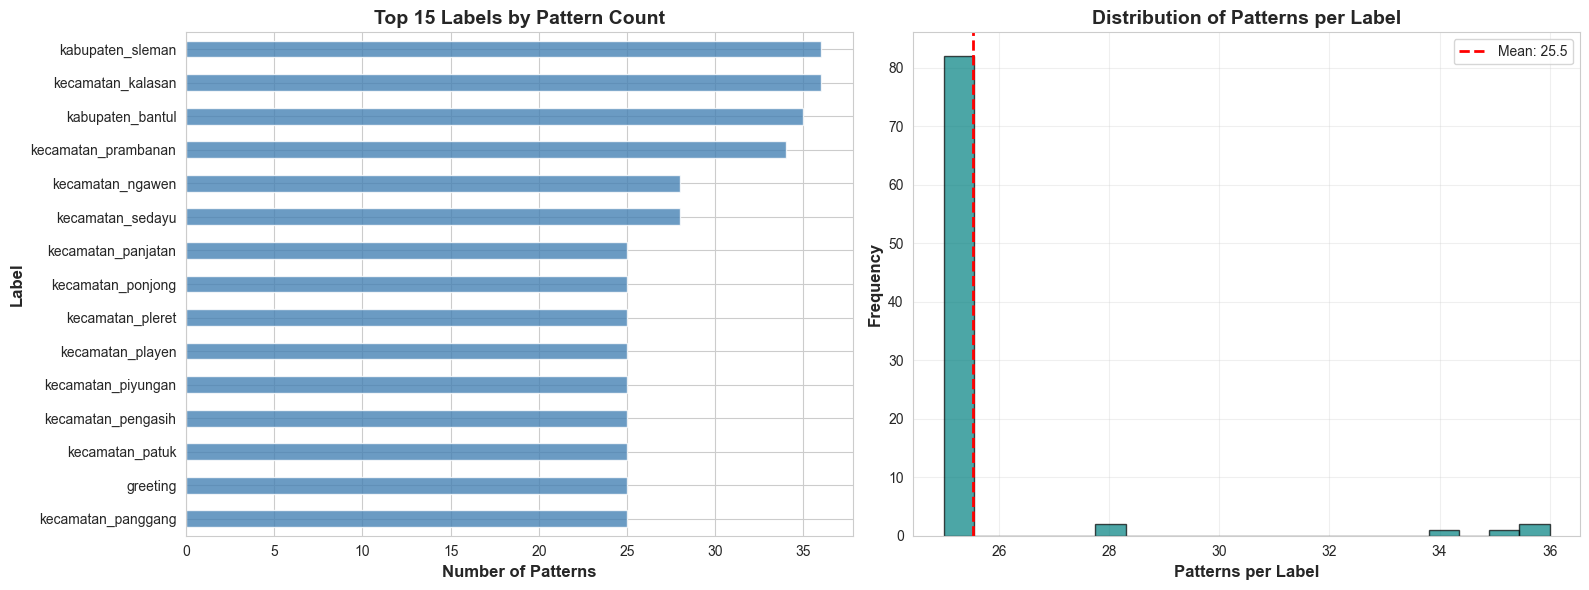

In [77]:
# Label distribution
label_counts = df['label'].value_counts()

print("=" * 80)
print("LABEL DISTRIBUTION")
print("=" * 80)
print(f"\nTop 10 labels:")
print(label_counts.head(10))

print(f"\nStatistics:")
print(f"  Mean: {label_counts.mean():.2f}")
print(f"  Median: {label_counts.median():.0f}")
print(f"  Min: {label_counts.min()}")
print(f"  Max: {label_counts.max()}")

# Visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

label_counts.head(15).plot(kind='barh', ax=ax1, color='steelblue', alpha=0.8)
ax1.set_xlabel('Number of Patterns', fontsize=12, fontweight='bold')
ax1.set_ylabel('Label', fontsize=12, fontweight='bold')
ax1.set_title('Top 15 Labels by Pattern Count', fontsize=14, fontweight='bold')
ax1.invert_yaxis()

ax2.hist(label_counts, bins=20, color='teal', alpha=0.7, edgecolor='black')
ax2.axvline(label_counts.mean(), color='red', linestyle='--', linewidth=2,
            label=f'Mean: {label_counts.mean():.1f}')
ax2.set_xlabel('Patterns per Label', fontsize=12, fontweight='bold')
ax2.set_ylabel('Frequency', fontsize=12, fontweight='bold')
ax2.set_title('Distribution of Patterns per Label', fontsize=14, fontweight='bold')
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 5. Text Normalization

In [78]:
def normalize_text(text):
    """
    Normalize text:
    - Lowercase (case folding)
    - Remove URLs
    - Remove emails
    - Remove special characters and numbers
    - Remove extra whitespace
    """
    text = text.lower()
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'\S+@\S+', '', text)
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    text = ' '.join(text.split())
    return text

print("=" * 80)
print("TEXT NORMALIZATION")
print("=" * 80)

print("\nBefore normalization:")
for i in range(5):
    print(f"  {i+1}. {df['pattern'].iloc[i]}")

df['normalized'] = df['pattern'].apply(normalize_text)

print("\nAfter normalization:")
for i in range(5):
    print(f"  {i+1}. {df['normalized'].iloc[i]}")

print("\n✓ Text normalization completed")

TEXT NORMALIZATION

Before normalization:
  1. halo
  2. hai
  3. hey
  4. hello
  5. hi

After normalization:
  1. halo
  2. hai
  3. hey
  4. hello
  5. hi

✓ Text normalization completed


## 6. Tokenization

In [79]:
# Word-level tokenization
print("=" * 80)
print("TOKENIZATION")
print("=" * 80)

df['tokens'] = df['normalized'].apply(lambda x: x.split())

print("\nExamples:")
for i in range(5):
    print(f"\n{i+1}. Original: {df['pattern'].iloc[i]}")
    print(f"   Normalized: {df['normalized'].iloc[i]}")
    print(f"   Tokens: {df['tokens'].iloc[i]}")

print("\n✓ Tokenization completed")

TOKENIZATION

Examples:

1. Original: halo
   Normalized: halo
   Tokens: ['halo']

2. Original: hai
   Normalized: hai
   Tokens: ['hai']

3. Original: hey
   Normalized: hey
   Tokens: ['hey']

4. Original: hello
   Normalized: hello
   Tokens: ['hello']

5. Original: hi
   Normalized: hi
   Tokens: ['hi']

✓ Tokenization completed


## 7. Stopword Removal

In [80]:
# SKIP STOPWORD REMOVAL FOR GREETING INTENTS
print("=" * 80)
print("STOPWORD REMOVAL - SKIPPED")
print("=" * 80)

print("IMPORTANT: Stopword removal DISABLED for chatbot intent classification")
print("Reason: Words like 'selamat' in 'selamat pagi' are CRITICAL for intent detection")
print("Removing stopwords destroys greeting intent meaning\n")

# Just copy tokens without removing stopwords
df['tokens_no_sw'] = df['tokens']

print("Comparison:")
for i in range(5):
    print(f"\n{i+1}. Original: {df['pattern'].iloc[i]}")
    print(f"   Tokens kept: {df['tokens_no_sw'].iloc[i]}")

print("\nStopword removal skipped - all words preserved")

STOPWORD REMOVAL - SKIPPED
IMPORTANT: Stopword removal DISABLED for chatbot intent classification
Reason: Words like 'selamat' in 'selamat pagi' are CRITICAL for intent detection
Removing stopwords destroys greeting intent meaning

Comparison:

1. Original: halo
   Tokens kept: ['halo']

2. Original: hai
   Tokens kept: ['hai']

3. Original: hey
   Tokens kept: ['hey']

4. Original: hello
   Tokens kept: ['hello']

5. Original: hi
   Tokens kept: ['hi']

Stopword removal skipped - all words preserved


## 8. Stemming

In [81]:
# Sastrawi stemming for Indonesian
print("=" * 80)
print("STEMMING")
print("=" * 80)

stemmer_factory = StemmerFactory()
stemmer = stemmer_factory.create_stemmer()

def stem_tokens(tokens):
    return [stemmer.stem(word) for word in tokens]

df['stemmed'] = df['tokens_no_sw'].apply(stem_tokens)

print("\nExamples:")
for i in range(5):
    print(f"\n{i+1}. Original: {df['pattern'].iloc[i]}")
    print(f"   No stopwords: {df['tokens_no_sw'].iloc[i]}")
    print(f"   Stemmed: {df['stemmed'].iloc[i]}")

print("\n✓ Stemming completed")

STEMMING

Examples:

1. Original: halo
   No stopwords: ['halo']
   Stemmed: ['halo']

2. Original: hai
   No stopwords: ['hai']
   Stemmed: ['hai']

3. Original: hey
   No stopwords: ['hey']
   Stemmed: ['hey']

4. Original: hello
   No stopwords: ['hello']
   Stemmed: ['hello']

5. Original: hi
   No stopwords: ['hi']
   Stemmed: ['hi']

✓ Stemming completed


## 9. Lemmatization

**Note**: Lemmatization untuk bahasa Indonesia belum tersedia di Sastrawi. Untuk project ini, kita hanya menggunakan stemming.

## 10. Text Length Analysis

TEXT LENGTH ANALYSIS

Original (after tokenization):
  Mean: 4.27
  Median: 4
  Min: 1
  Max: 10

After stopword removal:
  Mean: 4.27
  Median: 4
  Min: 1
  Max: 10

After stemming:
  Mean: 4.27
  Median: 4
  Min: 1
  Max: 10


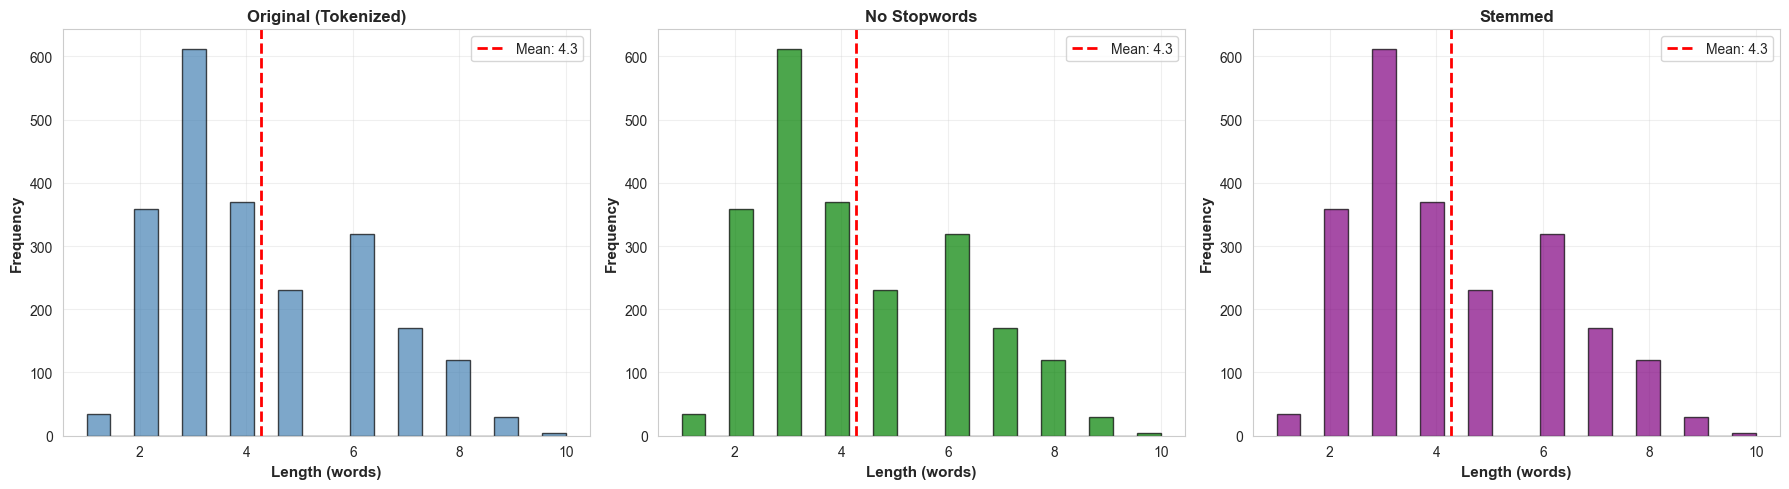

In [82]:
# Analyze text lengths after each step
df['len_original'] = df['tokens'].apply(len)
df['len_no_sw'] = df['tokens_no_sw'].apply(len)
df['len_stemmed'] = df['stemmed'].apply(len)

print("=" * 80)
print("TEXT LENGTH ANALYSIS")
print("=" * 80)

print("\nOriginal (after tokenization):")
print(f"  Mean: {df['len_original'].mean():.2f}")
print(f"  Median: {df['len_original'].median():.0f}")
print(f"  Min: {df['len_original'].min()}")
print(f"  Max: {df['len_original'].max()}")

print("\nAfter stopword removal:")
print(f"  Mean: {df['len_no_sw'].mean():.2f}")
print(f"  Median: {df['len_no_sw'].median():.0f}")
print(f"  Min: {df['len_no_sw'].min()}")
print(f"  Max: {df['len_no_sw'].max()}")

print("\nAfter stemming:")
print(f"  Mean: {df['len_stemmed'].mean():.2f}")
print(f"  Median: {df['len_stemmed'].median():.0f}")
print(f"  Min: {df['len_stemmed'].min()}")
print(f"  Max: {df['len_stemmed'].max()}")

# Visualization
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Original
axes[0].hist(df['len_original'], bins=20, color='steelblue', alpha=0.7, edgecolor='black')
axes[0].axvline(df['len_original'].mean(), color='red', linestyle='--', linewidth=2,
                label=f'Mean: {df["len_original"].mean():.1f}')
axes[0].set_xlabel('Length (words)', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Frequency', fontsize=11, fontweight='bold')
axes[0].set_title('Original (Tokenized)', fontsize=12, fontweight='bold')
axes[0].legend()
axes[0].grid(alpha=0.3)

# No stopwords
axes[1].hist(df['len_no_sw'], bins=20, color='green', alpha=0.7, edgecolor='black')
axes[1].axvline(df['len_no_sw'].mean(), color='red', linestyle='--', linewidth=2,
                label=f'Mean: {df["len_no_sw"].mean():.1f}')
axes[1].set_xlabel('Length (words)', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Frequency', fontsize=11, fontweight='bold')
axes[1].set_title('No Stopwords', fontsize=12, fontweight='bold')
axes[1].legend()
axes[1].grid(alpha=0.3)

# Stemmed
axes[2].hist(df['len_stemmed'], bins=20, color='purple', alpha=0.7, edgecolor='black')
axes[2].axvline(df['len_stemmed'].mean(), color='red', linestyle='--', linewidth=2,
                label=f'Mean: {df["len_stemmed"].mean():.1f}')
axes[2].set_xlabel('Length (words)', fontsize=11, fontweight='bold')
axes[2].set_ylabel('Frequency', fontsize=11, fontweight='bold')
axes[2].set_title('Stemmed', fontsize=12, fontweight='bold')
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 11. Vocabulary Analysis

VOCABULARY ANALYSIS

Original vocabulary size: 297 unique words
Stemmed vocabulary size: 286 unique words
Reduction: 11 words (3.7%)


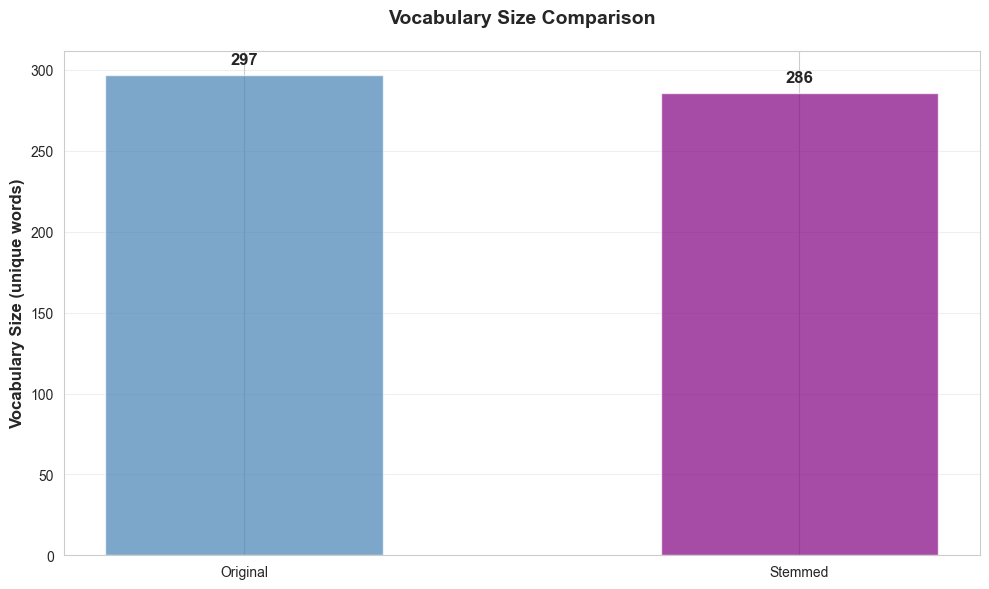

In [83]:
# Compare vocabulary size before and after preprocessing
original_vocab = set()
for tokens in df['tokens']:
    original_vocab.update(tokens)

stemmed_vocab = set()
for tokens in df['stemmed']:
    stemmed_vocab.update(tokens)

print("=" * 80)
print("VOCABULARY ANALYSIS")
print("=" * 80)

print(f"\nOriginal vocabulary size: {len(original_vocab)} unique words")
print(f"Stemmed vocabulary size: {len(stemmed_vocab)} unique words")
reduction = len(original_vocab) - len(stemmed_vocab)
reduction_pct = (reduction / len(original_vocab)) * 100
print(f"Reduction: {reduction} words ({reduction_pct:.1f}%)")

# Visualization
fig, ax = plt.subplots(figsize=(10, 6))

versions = ['Original', 'Stemmed']
sizes = [len(original_vocab), len(stemmed_vocab)]
colors = ['steelblue', 'purple']

bars = ax.bar(versions, sizes, color=colors, alpha=0.7, width=0.5)

for bar, size in zip(bars, sizes):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 5,
            f'{size}', ha='center', va='bottom', fontweight='bold', fontsize=12)

ax.set_ylabel('Vocabulary Size (unique words)', fontsize=12, fontweight='bold')
ax.set_title('Vocabulary Size Comparison', fontsize=14, fontweight='bold', pad=20)
ax.grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

## 12. Top Words Analysis

TOP 20 MOST FREQUENT WORDS (After Stemming)
   1. di                  : 685 occurrences
   2. wisata              : 563 occurrences
   3. apa                 : 489 occurrences
   4. tempat              : 399 occurrences
   5. ada                 : 349 occurrences
   6. mau                 : 256 occurrences
   7. ke                  : 253 occurrences
   8. mana                : 199 occurrences
   9. aja                 : 196 occurrences
  10. rekomendasi         : 186 occurrences
  11. libur               : 168 occurrences
  12. dong                : 155 occurrences
  13. spot                : 150 occurrences
  14. ga                  : 128 occurrences
  15. tau                 : 122 occurrences
  16. buat                : 120 occurrences
  17. camat               : 108 occurrences
  18. yang                : 106 occurrences
  19. info                : 104 occurrences
  20. saran               : 96 occurrences


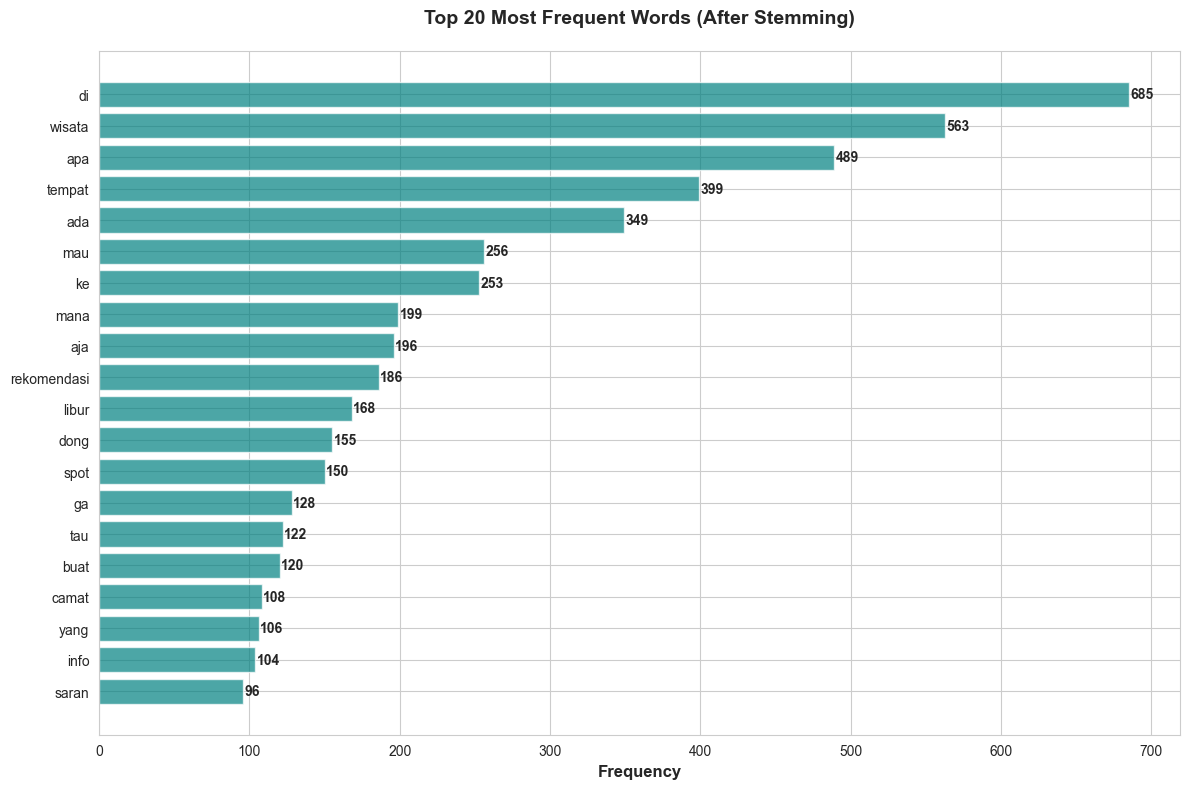

In [84]:
# Analyze most frequent words after stemming
all_stemmed_words = []
for tokens in df['stemmed']:
    all_stemmed_words.extend(tokens)

word_freq = Counter(all_stemmed_words)
top_20 = word_freq.most_common(20)

print("=" * 80)
print("TOP 20 MOST FREQUENT WORDS (After Stemming)")
print("=" * 80)

for i, (word, count) in enumerate(top_20, 1):
    print(f"  {i:2d}. {word:20s}: {count} occurrences")

# Visualization
fig, ax = plt.subplots(figsize=(12, 8))

words = [item[0] for item in top_20]
counts = [item[1] for item in top_20]

ax.barh(words, counts, color='teal', alpha=0.7)

for i, v in enumerate(counts):
    ax.text(v + 1, i, str(v), va='center', fontweight='bold')

ax.set_xlabel('Frequency', fontsize=12, fontweight='bold')
ax.set_title('Top 20 Most Frequent Words (After Stemming)', 
             fontsize=14, fontweight='bold', pad=20)
ax.invert_yaxis()

plt.tight_layout()
plt.show()

## 13. Save Preprocessed Data

In [85]:
# Save preprocessed text to CSV
print("=" * 80)
print("SAVING PREPROCESSED DATA")
print("=" * 80)

output_dir = '../data/preprocessed'
os.makedirs(output_dir, exist_ok=True)

# Join stemmed tokens back to text
df['processed_text'] = df['stemmed'].apply(lambda x: ' '.join(x))

# Save to CSV with 3 columns: pattern, processed_text, label
df_save = df[['pattern', 'processed_text', 'label']]
csv_path = f'{output_dir}/preprocessed_text.csv'
df_save.to_csv(csv_path, index=False, encoding='utf-8')

print(f"✓ Saved: {csv_path}")
print(f"  Shape: {df_save.shape}")
print(f"  Columns: {list(df_save.columns)}")
print(f"\n  Sample rows:")
print(df_save.head(5))

# Save vocabulary and preprocessing info
preprocessing_info = {
    'total_patterns': len(df),
    'unique_labels': len(set(labels)),
    'original_vocab_size': len(original_vocab),
    'stemmed_vocab_size': len(stemmed_vocab),
    'vocab_reduction': f"{reduction} words ({reduction_pct:.1f}%)",
    'avg_length_original': float(df['len_original'].mean()),
    'avg_length_stemmed': float(df['len_stemmed'].mean()),
    'preprocessing_steps': [
        '1. Text normalization (case folding, remove special chars)',
        '2. Tokenization (word-level)',
        '3. Stopword removal (Indonesian - Sastrawi)',
        '4. Stemming (Sastrawi)'
    ]
}

info_path = f'{output_dir}/preprocessing_info.json'
with open(info_path, 'w', encoding='utf-8') as f:
    json.dump(preprocessing_info, f, indent=2, ensure_ascii=False)

print(f"\n✓ Saved: {info_path}")

print("\n" + "=" * 80)
print("ALL FILES SAVED SUCCESSFULLY")
print("=" * 80)

SAVING PREPROCESSED DATA
✓ Saved: ../data/preprocessed/preprocessed_text.csv
  Shape: (2247, 3)
  Columns: ['pattern', 'processed_text', 'label']

  Sample rows:
  pattern processed_text     label
0    halo           halo  greeting
1     hai            hai  greeting
2     hey            hey  greeting
3   hello          hello  greeting
4      hi             hi  greeting

✓ Saved: ../data/preprocessed/preprocessing_info.json

ALL FILES SAVED SUCCESSFULLY


## 14. Summary

In [86]:
print("=" * 80)
print("PREPROCESSING SUMMARY - YOGA CHATBOT")
print("=" * 80)

print("\n📊 Dataset:")
print(f"  Total intents: {len(intents)}")
print(f"  Total patterns: {len(patterns)}")
print(f"  Unique labels: {len(set(labels))}")

print("\n🔄 Preprocessing Steps Completed:")
print("  1. ✓ Text Normalization")
print("     - Case folding (lowercase)")
print("     - Remove URLs, emails")
print("     - Remove special characters")
print("  2. ✓ Tokenization")
print("     - Word-level tokenization")
print("  3. ✓ Stopword Removal")
print("  4. ✓ Stemming")
print("     - Indonesian stemming using Sastrawi")

print("\n🔤 Vocabulary:")
print(f"  Original: {len(original_vocab)} unique words")
print(f"  Stemmed: {len(stemmed_vocab)} unique words")
print(f"  Reduction: {reduction} words ({reduction_pct:.1f}%)")

print("\n📏 Text Length:")
print(f"  Original mean: {df['len_original'].mean():.2f} words")
print(f"  After stopword removal: {df['len_no_sw'].mean():.2f} words")
print(f"  After stemming: {df['len_stemmed'].mean():.2f} words")

print("\n💾 Saved Files:")
print(f"  - preprocessed_text.csv ({df_save.shape[0]} rows, 3 columns)")
print(f"  - preprocessing_info.json")

print("\n✅ Next Steps:")
print("  1. ✓ Pattern Acquisition")
print("  2. ✓ Preprocessing (NLP)")
print("  3. → Feature Extraction")
print("      - Keras tokenization")
print("      - Padding sequences")
print("      - Label encoding")
print("      - Train-test split")
print("  4. → LSTM Modeling")
print("      - Word embedding layer")
print("      - LSTM architecture")
print("      - Model training")
print("  5. → Evaluation")
print("      - Accuracy, precision, recall, F1-score")
print("      - Confusion matrix")

print("\n" + "=" * 80)
print("✓ PREPROCESSING COMPLETE - Ready for Feature Extraction")
print("=" * 80)

PREPROCESSING SUMMARY - YOGA CHATBOT

📊 Dataset:
  Total intents: 88
  Total patterns: 2247
  Unique labels: 88

🔄 Preprocessing Steps Completed:
  1. ✓ Text Normalization
     - Case folding (lowercase)
     - Remove URLs, emails
     - Remove special characters
  2. ✓ Tokenization
     - Word-level tokenization
  3. ✓ Stopword Removal
  4. ✓ Stemming
     - Indonesian stemming using Sastrawi

🔤 Vocabulary:
  Original: 297 unique words
  Stemmed: 286 unique words
  Reduction: 11 words (3.7%)

📏 Text Length:
  Original mean: 4.27 words
  After stopword removal: 4.27 words
  After stemming: 4.27 words

💾 Saved Files:
  - preprocessed_text.csv (2247 rows, 3 columns)
  - preprocessing_info.json

✅ Next Steps:
  1. ✓ Pattern Acquisition
  2. ✓ Preprocessing (NLP)
  3. → Feature Extraction
      - Keras tokenization
      - Padding sequences
      - Label encoding
      - Train-test split
  4. → LSTM Modeling
      - Word embedding layer
      - LSTM architecture
      - Model training
  5.